# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Alice Miller, Emma Crawford, Nina Beadnell, Maciek Romanowski**

## Setup

In [2]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

In [5]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

This report investigates daily river water levels recorded at 392 monitoring stations across 35 counties in Scotland between 2014 and 2026. Using supervised and unsupervised machine learning techniques, we aim to identify meaningful patterns in river behaviour and investigate the potential for predicting flood events.

The data used in this report contains the river level monitoring stations (by name and by ID label), their geographical location (county of Scotland, as well as longitude and latitude) and the reported daily average, minimum and maximum water levels (in metres).

Two objectives are considered. First, clustering is used to group monitoring stations according to similarities in their water-level characteristics. Second, binary classification is used to predict whether a station will experience a flood based on observations from the preceding seven days.

Before modelling, we analyse the data for missing observations, outliers and differences in station coverage. Relevant features are then constructed to describe river properties and aid further analysis.

First, we consider clustering, an unsupervised machine learning task where, based on the constructed features, we try to group together stations with similar properties. Clustering is crucial in identifying trends, patterns and intrinsic relationships in the dataset. We implement the K-means++ and hierarchical clustering algorithms and compare their performance. We observe that all stations can be grouped into three separate groups: one containing all of the tidal stations, [input rest].

Second, we consider classification, a supervised machine learning task, where we aim to build a model to predict future flood events. We train and test various models to find the one with the best performance. Given that flood events are rare, we choose as a baseline a model which always predicts no flood. Our best performing model is [insert model].

Building on our classification model, we identify factors that can be used to predict flood events. These findings can help government agencies understand river behaviour and identify regions at high risk of flooding. By predicting floods before they occur, we aim to ease the strain on government and emergency services, and reduce the human cost of flooding [reference 1].

# Exploratory Data Analysis and Feature Engineering


Initial investigation of the data, seen in graph [Missing water-level observations across stations], indicates a significant proportion of the data is missing (30.64%). This is due to either the observation not being made, a particular observation station being decommissioned or not yet begun recording. Based on the heat map, we can see that almost no station have any recorded values before early 2017, and further analysis motivation the cut-off at [...]. We therefore decide to remove the first 908 days from out datasets.  It is also noted that the additional region of considerable missingness in 2021 is associated with the impact of Covid-19, which we kept in the dataset to maintain one continuous timeframe of investigation. Additionally we input missing dates as columns of NaNs to maintain a continuous time frame. We also ensured the dates ran in the correct chronological order. 


*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

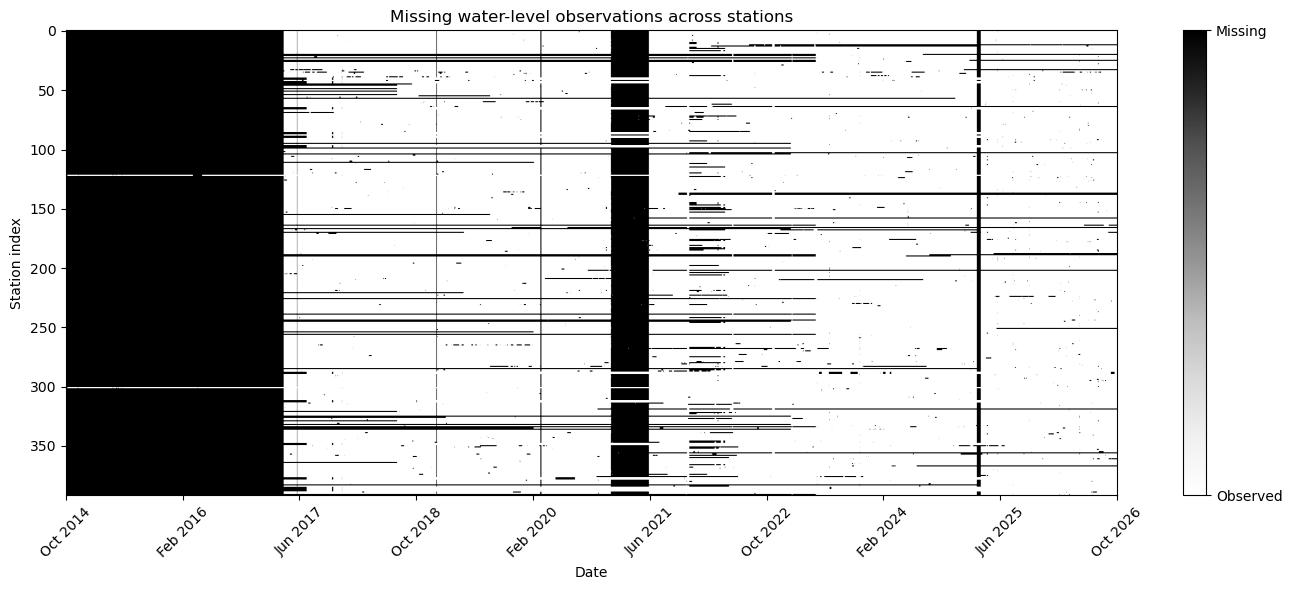

In [6]:
# Investigating the missing observations across different stations

# Select date columns
date_cols = df_avg.columns[3:]

data = df_avg[date_cols].apply(pd.to_numeric, errors="coerce")  # Make sure that the data has numerical values or NaN for missing values

# Convert columns to dates
data.columns = pd.to_datetime(date_cols, dayfirst=True)

# Sort chronologically and insert missing dates
data = data.sort_index(axis=1)

all_dates = pd.date_range(
    start=data.columns.min(),
    end=data.columns.max(),
    freq="D"
)

# If the date does NOT exist pandas creates a new column filled with NaN
data = data.reindex(columns=all_dates)

# Missing-data matrix: 1 = missing, 0 = observed
missing = data.isna().astype(int)

# Plot a heatmap
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(
    missing,
    aspect="auto",
    cmap="Greys"
)

# Date labels
ticks = np.linspace(0, len(all_dates) - 1, 10, dtype=int)

ax.set_xticks(ticks)
ax.set_xticklabels(
    all_dates[ticks].strftime("%b %Y"),
    rotation=45
)

ax.set_xlabel("Date")
ax.set_ylabel("Station index")
ax.set_title("Missing water-level observations across stations")

# Colourbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Observed", "Missing"])

plt.tight_layout()
plt.show()

We also identify "weird" values our in our data set, which could correspond to a different way of encoding missing data. Another reason for this might be the occurence of a flood event, when the equipement records abnormal values when the flood occurs. To account for this we decide to change all observation with values greater than absolute value of 30 to NaN. This allow to 


Potential outliers are present in the datasets, such as reports of river level exceeding 30m in elevation and falling below -30m, values that are simply impossible in context. This is likely due to human error, such as inputting an incorrect measure or misuse of or faulty measuring equipment. This led to the decision to ‘scrub’ these values from the data, and instead label them as no observation (NaN).

In [7]:
# Data preprocessing
def prepare_cluster(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    # Replace observations with |value| > 40 with NaN
    data = data.mask(data.abs() > 40)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(
        start=data.columns.min(),
        end=data.columns.max(),
        freq="D"
    )

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = prepare_cluster(df_avg)
minimum = prepare_cluster(df_min)
maximum = prepare_cluster(df_max)

# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [8]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] ERROR | Error while converting 'project.ipynb'
Traceback (most recent call last):
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\nbconvertapp.py", line 487, in export_single_notebook
    output, resources = self.exporter.from_filename(
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\templateexporter.py", line 386, in from_filename
    return super().from_filename(filename, resources, **kw)  # type:ignore[return-value]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\exporter.py", line 201, in from_filename
    return self.from_file(f, resources=resources, **kw)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\templateexporter.py", line 392, in from_file
    return su